# Single-cell multiome analysis with MultiVI

This tutorial analyzes the public **10x Genomics PBMC from a healthy donor, no
cell sorting (3k)** multiome dataset, in which RNA and chromatin accessibility
were measured in the same nuclei. It asks what the two measurements show
together that each shows only partly on its own.

The workflow judges each measurement separately during QC, builds an RNA-only
and an ATAC-only baseline, trains a paired MultiVI model on raw counts, audits
the joint representation for technical structure, and names broad PBMC
populations from observed RNA markers before checking them against observed
accessibility.

## Learning objectives

By the end, you should be able to:

- identify the Cell Ranger ARC files used for secondary multiome analysis;
- calculate RNA and ATAC QC metrics separately for the same nuclei;
- summarize which nuclei have usable RNA, usable ATAC, both, or neither;
- keep raw counts for modeling and normalized values for plots;
- build RNA-only (PCA) and ATAC-only (TF-IDF/LSI) baselines;
- register a MuData object and train, save, and reload paired MultiVI;
- audit the joint representation against technical covariates;
- compare RNA-only, ATAC-only, and joint clusters for the same nuclei;
- separate observed expression and observed accessibility from model output.

## Reproducibility and compute

Create the environment with `environment.yml`, then run
`scripts/download_data.sh` and `scripts/prepare_fragment_metrics.sh`.

The fragment file is about 540 MB. The rendered notebook reloads a model
trained by `scripts/run_multivi.py` on a CPU. `OMP_NUM_THREADS` is set to 1
below and Scanpy is imported before scvi-tools. On macOS the PyTorch and
scikit-learn wheels each bundle an OpenMP runtime. In this environment, MultiVI
training stalled after Scanpy's neighbor and UMAP steps without the thread
limit, and importing scvi-tools (and with it PyTorch) before Scanpy crashed
numba's parallel QC code.

In [1]:
import os
import sys
import json
import logging
import warnings
from importlib.metadata import version
from pathlib import Path

os.environ.setdefault("XDG_CACHE_HOME", "/tmp/learn_gencore_multiome_xdg")
os.environ.setdefault("MPLCONFIGDIR", "/tmp/learn_gencore_multiome_mpl")
os.environ.setdefault("NUMBA_CACHE_DIR", "/tmp/learn_gencore_multiome_numba")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("KMP_WARNINGS", "0")
warnings.filterwarnings("ignore", message="IProgress not found.*")

import anndata as ad
import matplotlib.pyplot as plt
import pandas as pd
# Import Scanpy before scvi-tools. In this environment, importing scvi-tools
# (and with it PyTorch) first made numba's parallel QC code crash the kernel.
import scanpy as sc
import scvi
from IPython.display import display

cwd = Path.cwd().resolve()
candidates = [
    cwd.parent if cwd.name == "notebooks" else cwd,
    cwd / "source" / "transcriptomics" / "multiome_tutorial",
]
tutorial_dir = next(path for path in candidates if (path / "scripts").exists())
repo_root = tutorial_dir.parents[2]
raw_dir = tutorial_dir / "data" / "raw"
processed_dir = tutorial_dir / "data" / "processed"
results_dir = tutorial_dir / "results"
figure_dir = repo_root / "source" / "img" / "transcriptomics" / "multiome"
sys.path.insert(0, str(tutorial_dir / "scripts"))

from multiome_workflow import (
    DC_MARKERS,
    POPULATION_MARKERS,
    T_STATE_MARKERS,
    add_qc_flags,
    assign_populations,
    atac_baseline,
    build_embedding_graph,
    build_multivi_input,
    check_observed_libraries,
    choose_qc_thresholds,
    cluster_qc_table,
    clustering_agreement,
    compare_rna_groups,
    latent_qc_correlations,
    latent_qc_correlations_within,
    load_multiome_dataset,
    load_multivi,
    choose_marker_loci,
    locus_accessibility,
    marker_locus_specificity,
    mitochondrial_link,
    marker_detection,
    marker_evidence,
    normalize_rna,
    plot_atac_qc,
    plot_baselines,
    plot_cluster_agreement,
    plot_cluster_qc,
    plot_embedding_comparison,
    plot_fragment_length,
    plot_joint_cell_calling,
    plot_joint_qc,
    plot_latent_qc_correlations,
    plot_marker_evidence,
    plot_marker_loci,
    plot_multivi_umap,
    plot_rna_qc,
    plot_training_history,
    population_palette,
    resolution_check,
    qc_reason_counts,
    retention_table,
    rna_baseline,
    save_figure,
    score_doublets,
    score_populations,
    select_atac_features,
    select_rna_features,
    small_group_masks,
    split_population_by_depth,
    set_plot_style,
    subset_paired,
    train_multivi,
    training_history_frame,
    validate_cache_manifest,
    write_cache_manifest,
    write_results,
)

set_plot_style()
scvi.settings.verbosity = logging.WARNING
for package in ["scanpy", "mudata", "muon", "scvi-tools", "torch"]:
    print(f"{package}: {version(package)}")

scanpy: 1.11.5
mudata: 0.3.3
muon: 0.1.7
scvi-tools: 1.4.2
torch: 2.14.1


## 1. Check the public inputs

The filtered matrix contains RNA and peak counts for called nuclei only.
`per_barcode_metrics.csv` also covers background barcodes, so it shows how
Cell Ranger ARC separated nuclei from empty droplets. The fragment file is
needed for fragment periodicity and nucleosome signal.

The dataset page is:
https://www.10xgenomics.com/datasets/pbmc-from-a-healthy-donor-no-cell-sorting-3-k-1-standard-2-0-0

In [2]:
required_inputs = [
    (raw_dir, "filtered_feature_bc_matrix.h5", "raw"),
    (raw_dir, "per_barcode_metrics.csv", "raw"),
    (raw_dir, "atac_peak_annotation.tsv", "raw"),
    (raw_dir, "atac_fragments.tsv.gz", "raw"),
    (raw_dir, "atac_fragments.tsv.gz.tbi", "raw"),
    (processed_dir, "fragment_metrics.tsv", "processed"),
    (processed_dir, "fragment_length_histogram.tsv", "processed"),
]
input_status = pd.DataFrame(
    {
        "location": [location for _, _, location in required_inputs],
        "file": [name for _, name, _ in required_inputs],
        "present": [(directory / name).exists() for directory, name, _ in required_inputs],
        "size_MB": [
            round((directory / name).stat().st_size / 1e6, 1)
            if (directory / name).exists()
            else None
            for directory, name, _ in required_inputs
        ],
    }
)
display(input_status)
assert input_status["present"].all(), (
    "Run scripts/download_data.sh and scripts/prepare_fragment_metrics.sh "
    "before continuing."
)

,location,file,present,size_MB
0,raw,filtered_feature_bc_matrix.h5,True,31.8
1,raw,per_barcode_metrics.csv,True,72.1
2,raw,atac_peak_annotation.tsv,True,4.5
3,raw,atac_fragments.tsv.gz,True,537.3
4,raw,atac_fragments.tsv.gz.tbi,True,0.6
5,processed,fragment_metrics.tsv,True,0.1
6,processed,fragment_length_histogram.tsv,True,0.0


## 2. Split the matrix into RNA and ATAC objects

Cell Ranger ARC stores genes and peaks in one matrix. The loader splits them by
`feature_types`, keeps raw counts in `layers["counts"]`, and gives both objects
the same per-nucleus metadata. The identity columns (`cell_id`, `sample_id`,
`donor_id`, `modality_status`, `has_rna`, `has_atac`) are set now so that later
analyses that mix paired and single-modality nuclei can rely on them.

In this ARC 2.0.0 output, `gex_umis_count` and `gex_genes_count` are zero for
every barcode. Exonic plus intronic UMIs equal the matrix totals, so the loader
uses those columns instead.

In [3]:
rna, atac, barcode_metrics = load_multiome_dataset(raw_dir, processed_dir)
print(rna)
print(atac)
assert rna.obs_names.equals(atac.obs_names)

/opt/homebrew/Caskroom/miniconda/base/envs/gencore-multiome-multivi/lib/python3.11/site-packages/anndata/_core/anndata.py:1825: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 3009 × 36601
    obs: 'cell_id', 'original_nucleus_id', 'sample_id', 'donor_id', 'modality_status', 'has_rna', 'has_atac', 'atac_barcode', 'gex_exonic_umis', 'gex_intronic_umis', 'atac_raw_reads', 'atac_dup_reads', 'atac_mitochondrial_reads', 'atac_fragments', 'atac_TSS_fragments', 'atac_peak_region_fragments', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'log10_umis', 'intronic_fraction', 'log10_fragments', 'frip', 'tss_fraction', 'duplicate_fraction', 'atac_mitochondrial_fraction', 'nucleosome_signal'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    layers: 'counts'
AnnData object with n_obs × n_vars = 3009 × 81156
    obs: 'cell_id', 'original_nucleus_id', 'sample_id', 'donor_id', 'modality_status', 'has_rna', 'has_atac', 'atac_barcode', 'gex_exonic_umis', 'gex_intronic_umis', 'atac_raw_reads', 'atac_dup_reads', 'atac_mitochondrial_reads', 'a

## 3. Review joint cell calling and fragment periodicity

Cell Ranger ARC calls a barcode a nucleus using both measurements. Called
nuclei should separate from background barcodes in RNA UMIs and ATAC fragments
together. The fragment-length curve should show a nucleosome-free component
and periodic mono- and di-nucleosomal structure.

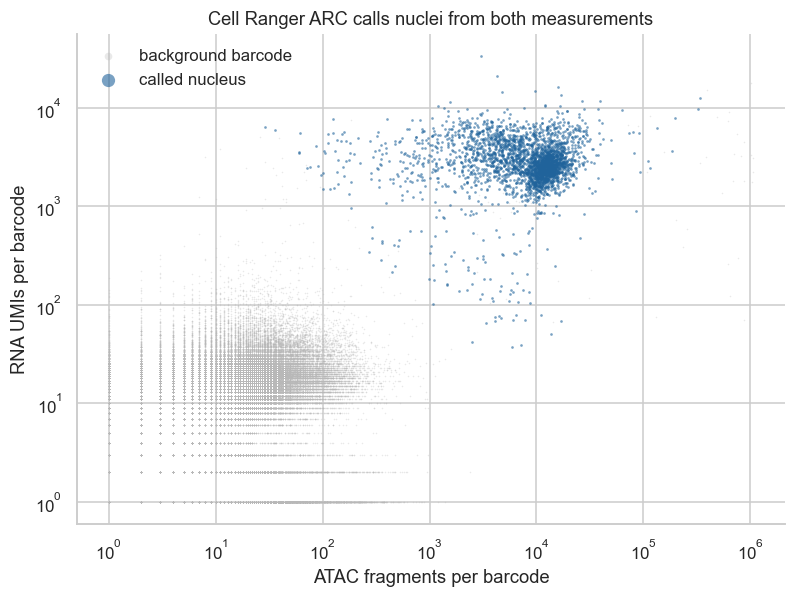

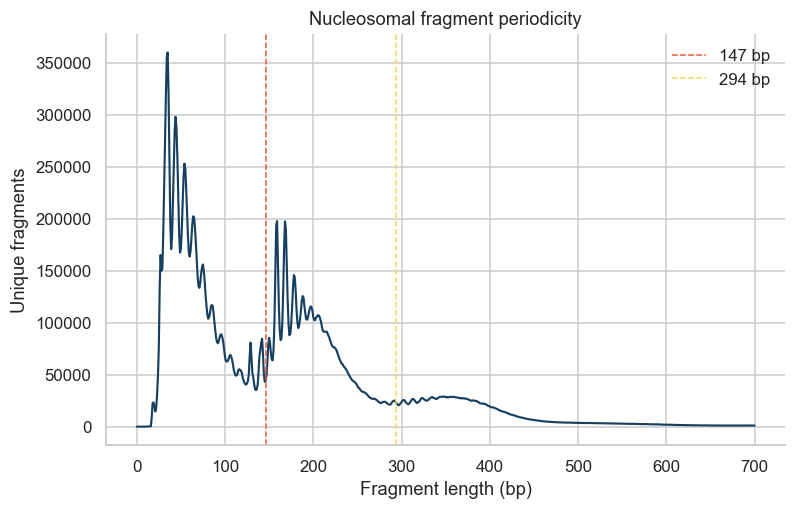

In [4]:
fig = plot_joint_cell_calling(barcode_metrics)
save_figure(fig, figure_dir / "01_joint_cell_calling.png")
plt.show()

fig = plot_fragment_length(processed_dir)
save_figure(fig, figure_dir / "02_fragment_length.png")
plt.show()

## 4. Flag RNA and ATAC quality separately

Each measurement gets its own review flags. RNA depth and gene-count tails use
the 2.5th percentile starting rule from the scRNA tutorial, and mitochondrial
UMIs use its 97.5th percentile. ATAC FRiP and TSS fraction use the 1st
percentile and nucleosome signal the 99th percentile, as in the scATAC
tutorial. Upper depth tails use the 99.5th percentile in both. These are
review thresholds for this dataset, not universal cutoffs.

Scrublet scores droplets from RNA. A doublet droplet contains two nuclei, so a
predicted doublet is excluded from the paired model whatever its ATAC metrics.

,threshold
min_umis,480.00
max_umis,9880.00
min_genes,250.00
max_pct_mt,27.50
min_fragments,470.00
max_fragments,49790.00
min_frip,0.32
min_tss_fraction,0.26
max_nucleosome_signal,1.26


,flag,n_nuclei
0,low RNA UMIs,75
1,high RNA UMIs,15
2,few detected genes,75
3,high mitochondrial fraction,75
4,low ATAC fragments,74
5,high ATAC fragments,16
6,low FRiP,30
7,low TSS fraction,29
8,high nucleosome signal,29
9,predicted doublet,74


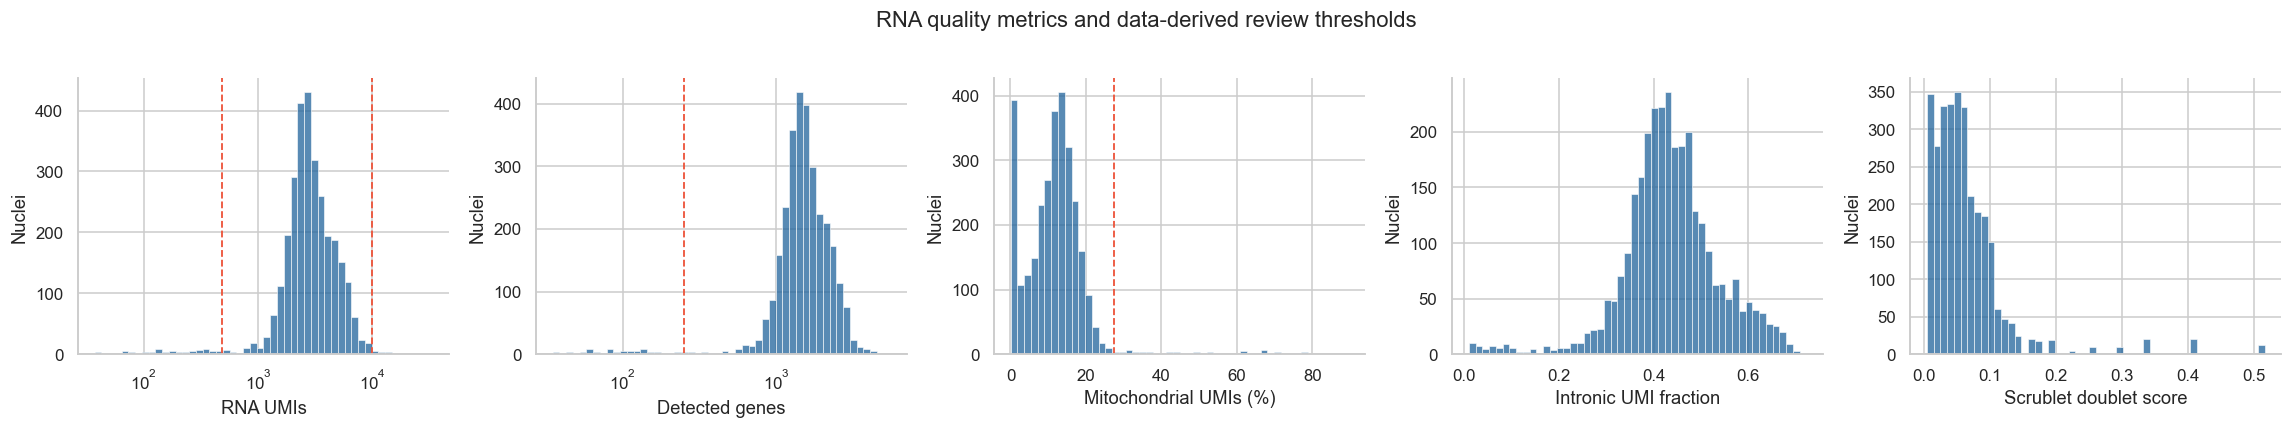

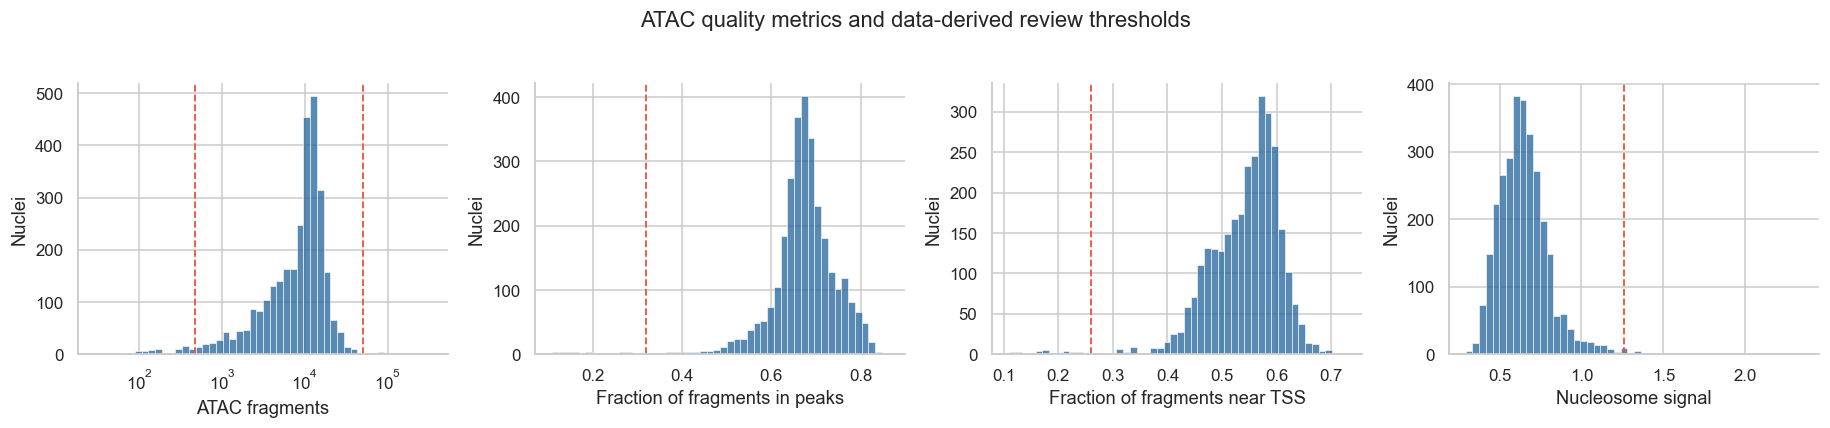

In [5]:
score_doublets(rna, seed=17)
thresholds = choose_qc_thresholds(rna.obs)
add_qc_flags(rna.obs, thresholds)
atac.obs = rna.obs.copy()

display(pd.Series(thresholds, name="threshold").to_frame())
display(qc_reason_counts(rna.obs))

fig = plot_rna_qc(rna.obs, thresholds)
save_figure(fig, figure_dir / "03_rna_qc.png")
plt.show()

fig = plot_atac_qc(rna.obs, thresholds)
save_figure(fig, figure_dir / "04_atac_qc.png")
plt.show()

## 5. Summarize which measurements each nucleus can contribute

Combining the flags gives four groups: both measurements usable, RNA only,
ATAC only, or neither. This tutorial's paired model keeps nuclei that pass both
and are not predicted doublets. Nuclei with one usable measurement are recorded
rather than discarded, because a mixed paired and single-modality model could
use them.

,qc_category,qc_doublet,n_nuclei,retained_for_paired_model
0,pass both,False,2718,True
1,pass both,True,67,False
2,RNA only,False,100,False
3,RNA only,True,2,False
4,ATAC only,False,98,False
5,ATAC only,True,5,False
6,neither,False,19,False
7,neither,True,0,False


,"median, ATAC-only nuclei"
total_counts,320.000000
pct_counts_mt,31.616343
atac_fragments,4431.000000
frip,0.716848
tss_fraction,0.586890


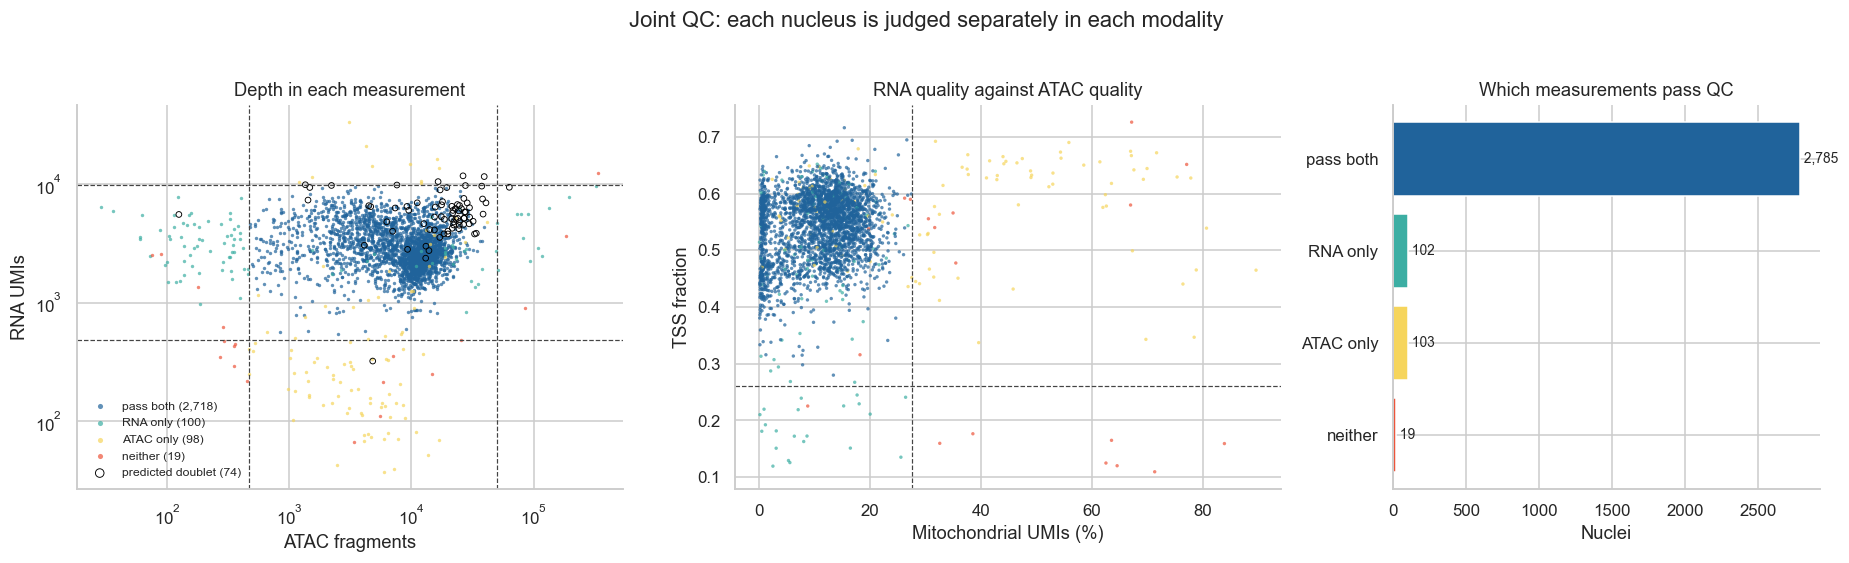

In [6]:
display(retention_table(rna.obs))

low_rna = rna.obs["qc_category"].eq("ATAC only")
display(
    rna.obs.loc[low_rna, ["total_counts", "pct_counts_mt", "atac_fragments", "frip", "tss_fraction"]]
    .median()
    .rename("median, ATAC-only nuclei")
    .to_frame()
)

fig = plot_joint_qc(rna.obs, thresholds)
save_figure(fig, figure_dir / "05_joint_qc.png")
plt.show()

## 6. Select features and build single-modality baselines

The model uses the 3,000 most variable nuclear genes (Seurat v3 rule on raw
counts) and the 30,000 peaks with the largest binary accessibility variance
among peaks detected in at least 30 nuclei. Mitochondrial genes and their
nuclear MTRNR2L copies are excluded from the modeled genes: in nuclei their
counts follow mitochondrial RNA carried over with attached cytoplasm, and vary
with how cleanly each nucleus was isolated rather than with nuclear gene
expression.

The baselines show what each measurement resolves on its own: PCA on scaled,
log-normalized RNA, and TF-IDF followed by LSI on the same peaks. LSI
components that track sequencing depth (absolute correlation above 0.5 with
log10 fragments) are dropped. Normalized values are used for these baselines
and for plots only; MultiVI receives raw counts.

In [7]:
rna_paired, atac_paired = subset_paired(rna, atac)
genes = select_rna_features(rna_paired, n_top_genes=3_000)
peaks = select_atac_features(atac_paired, min_cells_per_peak=30, max_peaks=30_000)
print(f"Paired nuclei: {rna_paired.n_obs:,}")
print(f"Peaks detected in at least 30 nuclei: {int((atac_paired.var['n_cells'] >= 30).sum()):,}")
print(f"Model genes: {len(genes):,}; model peaks: {len(peaks):,}")

normalize_rna(rna_paired)
container = ad.AnnData(obs=rna_paired.obs.copy())
container.obsm["X_pca_rna"] = rna_baseline(rna_paired, genes, seed=17)
container.obsm["X_lsi_atac"], lsi_depth = atac_baseline(atac_paired, peaks)
display(lsi_depth.head())

Paired nuclei: 2,718
Peaks detected in at least 30 nuclei: 64,305
Model genes: 3,000; model peaks: 30,000


/opt/homebrew/Caskroom/miniconda/base/envs/gencore-multiome-multivi/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


/opt/homebrew/Caskroom/miniconda/base/envs/gencore-multiome-multivi/lib/python3.11/site-packages/muon/_core/preproc.py:31: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  if Version(scanpy.__version__) < Version("1.10"):


,component,depth_correlation,used
0,1,0.992456,False
1,2,0.187995,True
2,3,-0.120372,True
3,4,-0.038116,True
4,5,-0.117822,True


## 7. Build the MultiVI input and check observed libraries

MultiVI decides that a nucleus is missing a modality when its counts in that
modality sum to zero. In a paired analysis every nucleus was measured in both,
so after feature selection every nucleus must still have counts in both
modalities. Otherwise MultiVI would treat it as unmeasured in one of them.

In [8]:
mdata = build_multivi_input(rna_paired, atac_paired, genes, peaks)
print(mdata)
display(check_observed_libraries(mdata))

MuData object with n_obs × n_vars = 2718 × 33000
  obs:	'cell_id', 'original_nucleus_id', 'sample_id', 'donor_id', 'modality_status', 'has_rna', 'has_atac', 'atac_barcode', 'gex_exonic_umis', 'gex_intronic_umis', 'atac_raw_reads', 'atac_dup_reads', 'atac_mitochondrial_reads', 'atac_fragments', 'atac_TSS_fragments', 'atac_peak_region_fragments', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'log10_umis', 'intronic_fraction', 'log10_fragments', 'frip', 'tss_fraction', 'duplicate_fraction', 'atac_mitochondrial_fraction', 'nucleosome_signal', 'doublet_score', 'predicted_doublet', 'qc_rna_low_umis', 'qc_rna_high_umis', 'qc_rna_low_genes', 'qc_rna_high_mt', 'qc_atac_low_fragments', 'qc_atac_high_fragments', 'qc_atac_low_frip', 'qc_atac_low_tss', 'qc_atac_high_nucleosome', 'qc_pass_rna', 'qc_pass_atac', 'qc_reason_rna', 'qc_reason_atac', 'qc_category', 'qc_doublet', 'qc_pass_joint'
  var:	'gene_ids', 'feature_types', 'genome', 'interval'
  2 modalities
    rna:	2718 x 3000
      var:	

/opt/homebrew/Caskroom/miniconda/base/envs/gencore-multiome-multivi/lib/python3.11/site-packages/mudata/_core/mudata.py:1403: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/opt/homebrew/Caskroom/miniconda/base/envs/gencore-multiome-multivi/lib/python3.11/site-packages/mudata/_core/mudata.py:1275: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)


,modality,features,nuclei,nuclei_with_zero_counts,min_counts,median_counts
0,rna,3000,2718,0,60.0,398.5
1,atac,30000,2718,0,479.0,11225.5


## 8. Train or reload MultiVI

Set `RUN_TRAINING = True` to fit the model in this notebook. The rendered copy
reloads the model generated by `scripts/run_multivi.py`.

All nuclei come from one paired sample, so no `batch_key` is passed. When
paired and single-modality nuclei are combined, the scvi-tools MultiVI tutorial
asks for the main `batch_key` to be the modality, with other batches passed as
`categorical_covariate_keys`.

/opt/homebrew/Caskroom/miniconda/base/envs/gencore-multiome-multivi/lib/python3.11/site-packages/torch/nn/modules/linear.py:124: UserWarning: Initializing zero-element tensors is a no-op
  init.kaiming_uniform_(self.weight, a=math.sqrt(5))


MultiVI Model with the following params: 
n_genes: 3000, n_regions: 30000, n_proteins: 0, n_hidden: 128, n_latent: 11, n_layers_encoder: 2, n_layers_decoder:
2, dropout_rate: 0.1, latent_distribution: normal, deep injection: False, gene_likelihood: zinb, 
gene_dispersion:gene, Mod.Weights: equal, Mod.Penalty: Jeffreys, protein_dispersion: protein
Training status: Trained
Model's adata is minified?: False
Model's adata is minified?: False

,value
max_epochs,500.0
n_top_genes,3000.0
max_peaks,30000.0
min_cells_per_peak,30.0
resolution,0.8
seed,17.0


Epochs trained: 377


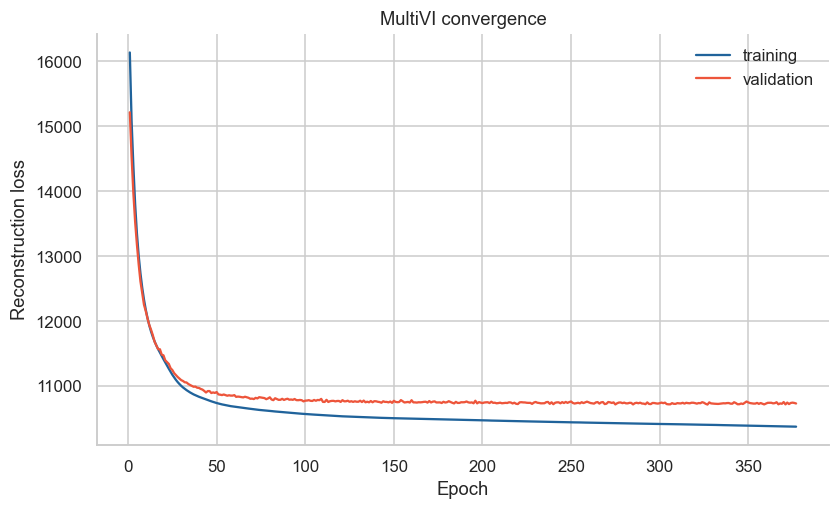

In [9]:
RUN_TRAINING = False
model_dir = results_dir / "models" / "multivi_pbmc_paired"
manifest_path = results_dir / "multivi_cache_manifest.json"
history_path = results_dir / "multivi_training_history.tsv"
parameters = {
    "max_epochs": 500,
    "n_top_genes": 3_000,
    "max_peaks": 30_000,
    "min_cells_per_peak": 30,
    "resolution": 0.8,
    "seed": 17,
}

if RUN_TRAINING:
    manifest = write_cache_manifest(mdata, manifest_path, parameters=parameters)
    model = train_multivi(mdata, model_dir=model_dir, max_epochs=500, seed=17)
    history = training_history_frame(model)
    history.to_csv(history_path, sep="\t", index=False)
else:
    required_cache = [model_dir / "model.pt", history_path, manifest_path]
    missing_cache = [str(path) for path in required_cache if not path.exists()]
    if missing_cache:
        raise FileNotFoundError(
            "Cached MultiVI outputs are missing. Run `python scripts/run_multivi.py` "
            "from the tutorial directory, or set RUN_TRAINING = True. Missing: "
            + ", ".join(missing_cache)
        )
    manifest = validate_cache_manifest(mdata, manifest_path)
    model = load_multivi(mdata, model_dir)
    history = pd.read_csv(history_path, sep="\t")

print(model)
display(pd.Series(manifest["parameters"], name="value").to_frame())
print(f"Epochs trained: {history['reconstruction_loss_train'].notna().sum()}")
fig = plot_training_history(history)
save_figure(fig, figure_dir / "07_multivi_training.png")
plt.show()

## 9. Build graphs and clusters for all three representations

The same graph, UMAP, and Leiden settings are applied to the RNA-only PCA, the
ATAC-only LSI, and the MultiVI latent space. The three UMAPs are separate
coordinate systems; compare which nuclei group together, not their positions.

rna: 14 clusters


atac: 10 clusters


multivi: 17 clusters


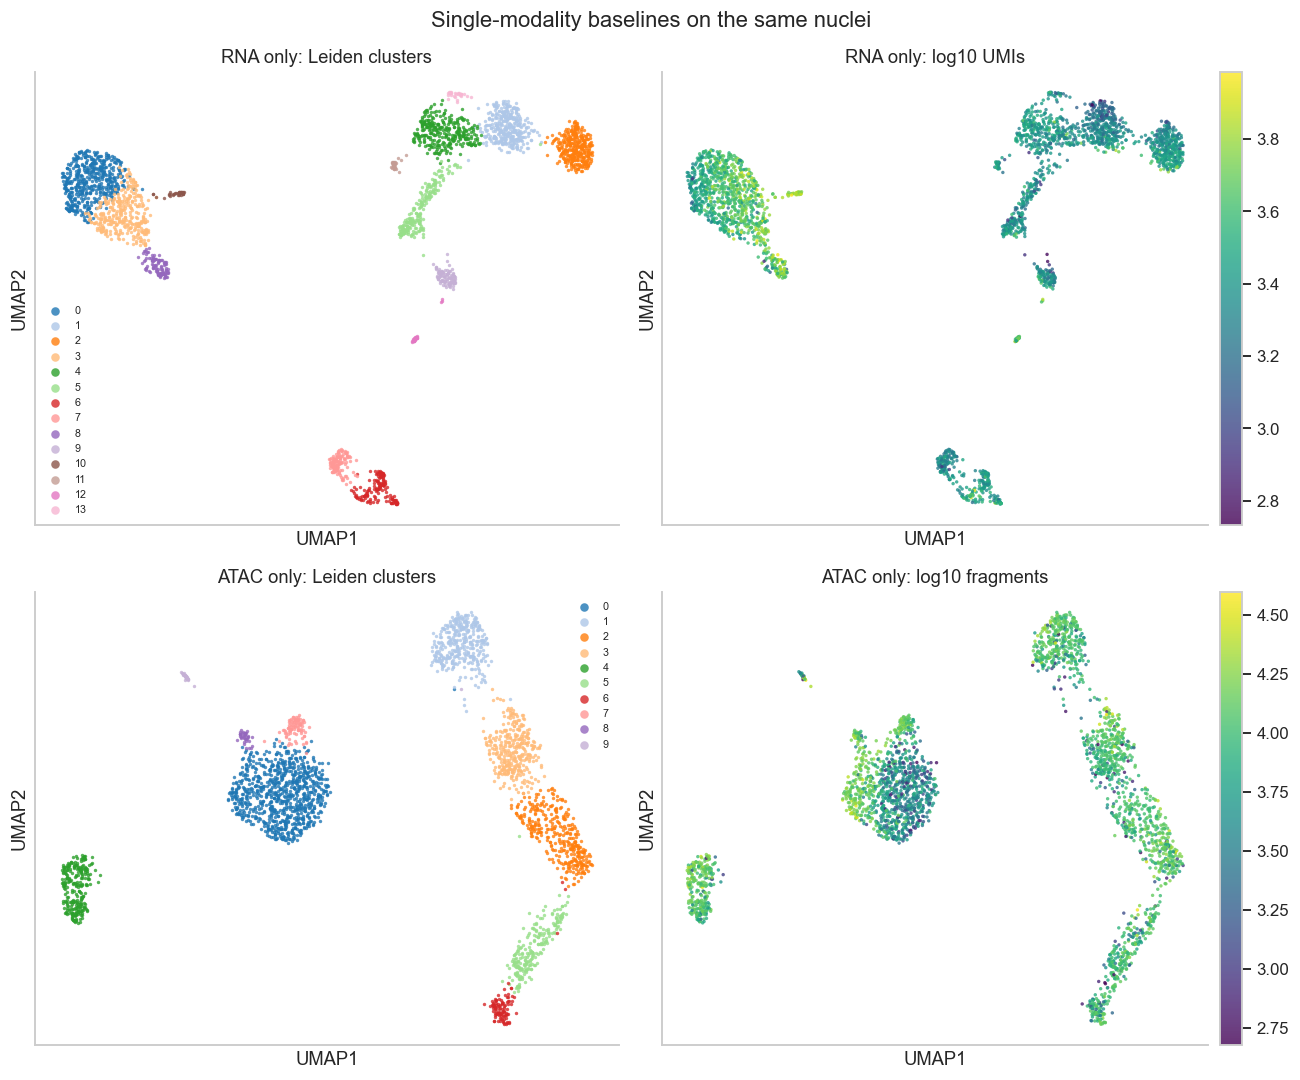

In [10]:
container.obsm["X_multivi"] = mdata.obsm["X_multivi"]
for rep_key, name in [("X_pca_rna", "rna"), ("X_lsi_atac", "atac"), ("X_multivi", "multivi")]:
    build_embedding_graph(container, rep_key, name, resolution=0.8, seed=17)
    print(f"{name}: {container.obs[f'leiden_{name}'].nunique()} clusters")

fig = plot_baselines(container)
save_figure(fig, figure_dir / "06_single_modality_baselines.png")
plt.show()

## 10. Audit the joint representation

A converged model can still organize nuclei by depth or quality. Correlate each
latent dimension with RNA and ATAC QC metrics, then inspect the UMAP and the
cluster-level QC distributions.

,component,metric,correlation
22,3,tss_fraction,-0.697970
46,6,tss_fraction,0.537354
16,3,log10_umis,0.515109
40,6,log10_umis,-0.502053
68,9,log10_fragments,-0.486144
72,10,log10_umis,-0.447980
0,1,log10_umis,-0.441272
69,9,frip,0.422308
78,10,tss_fraction,0.419572
79,10,nucleosome_signal,0.408692


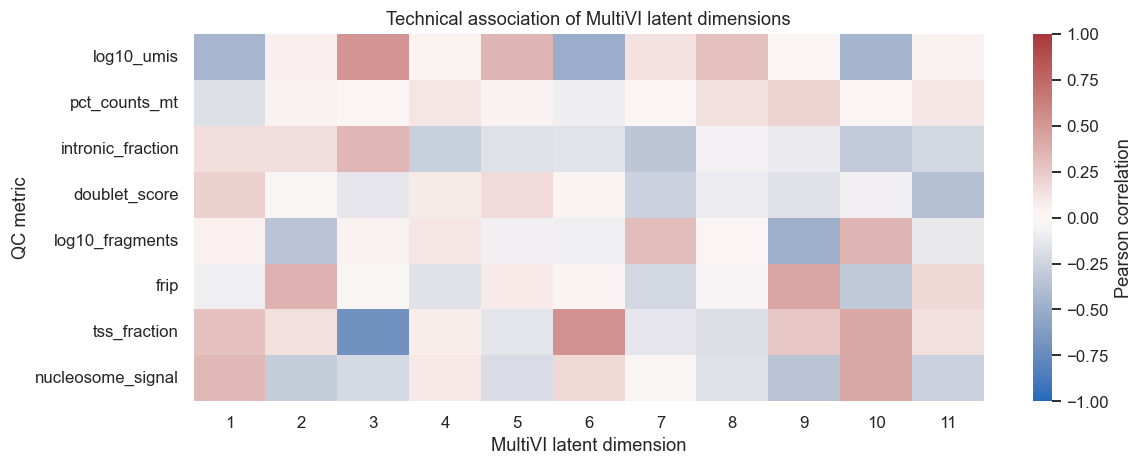

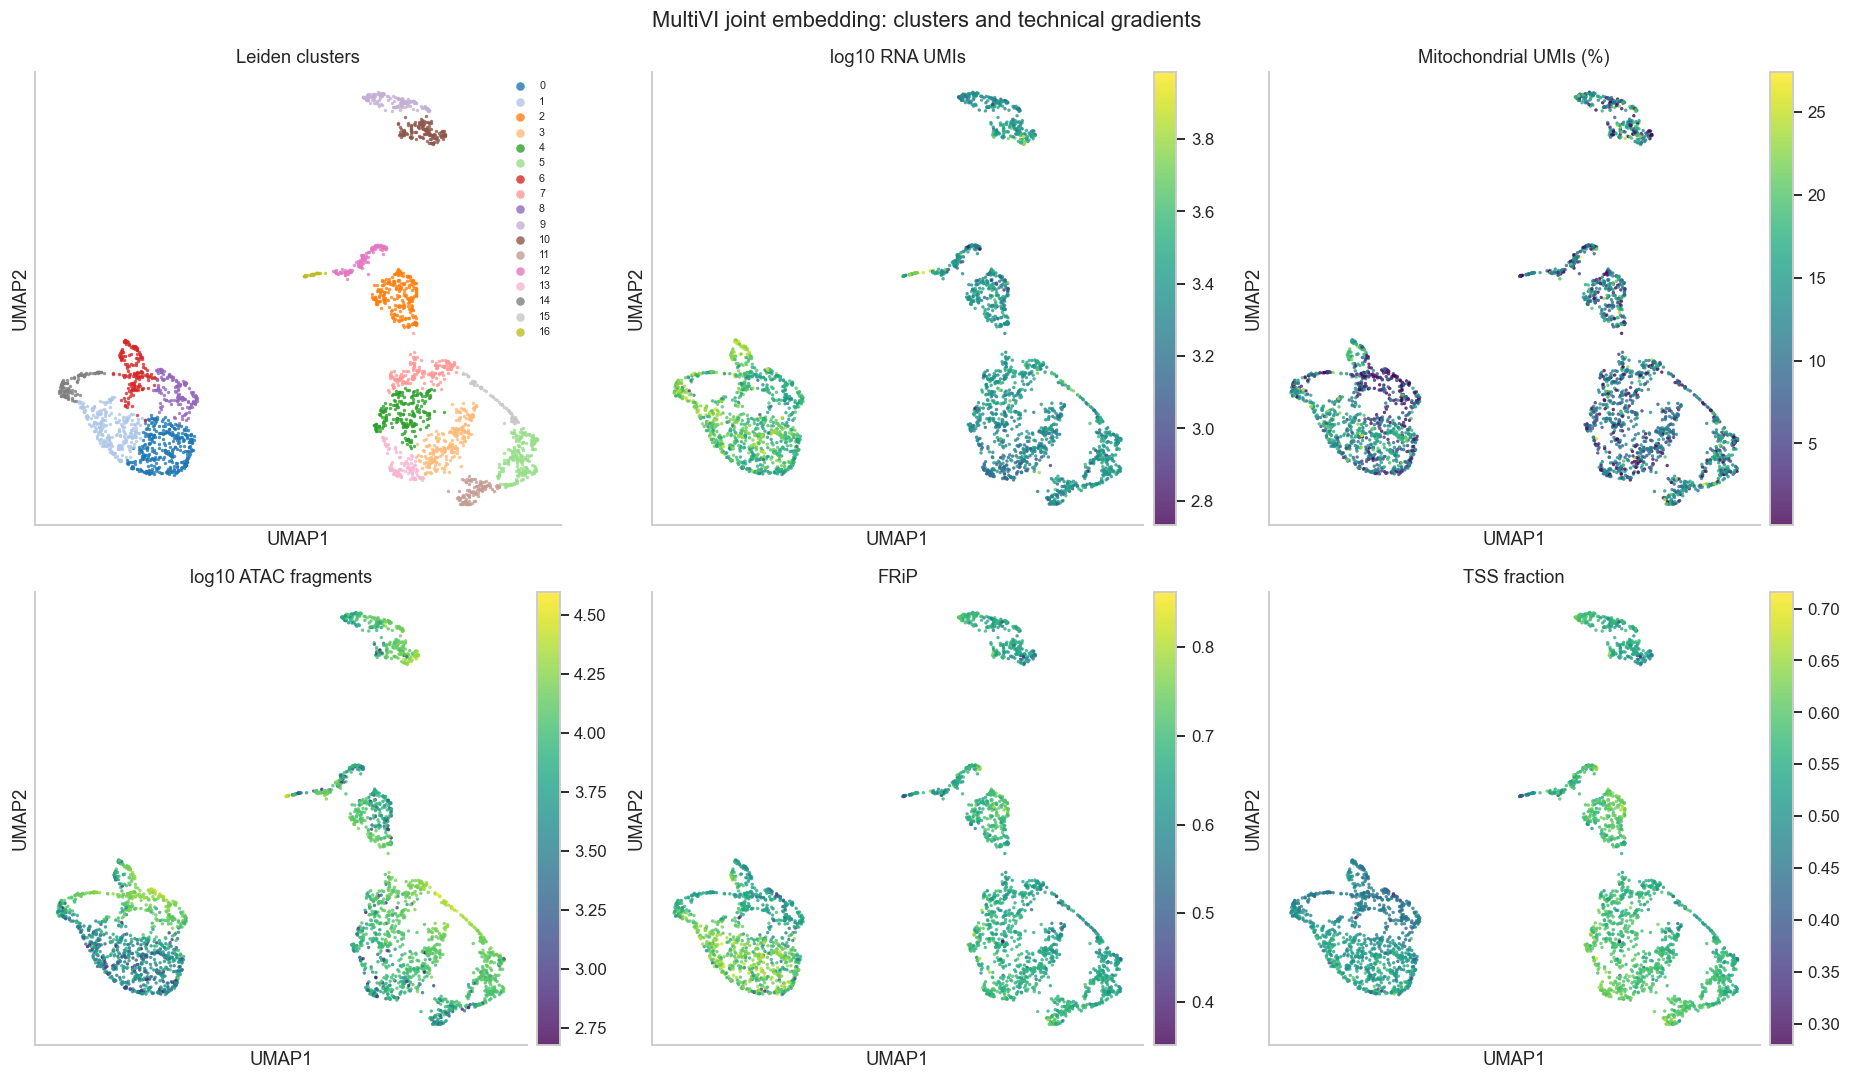

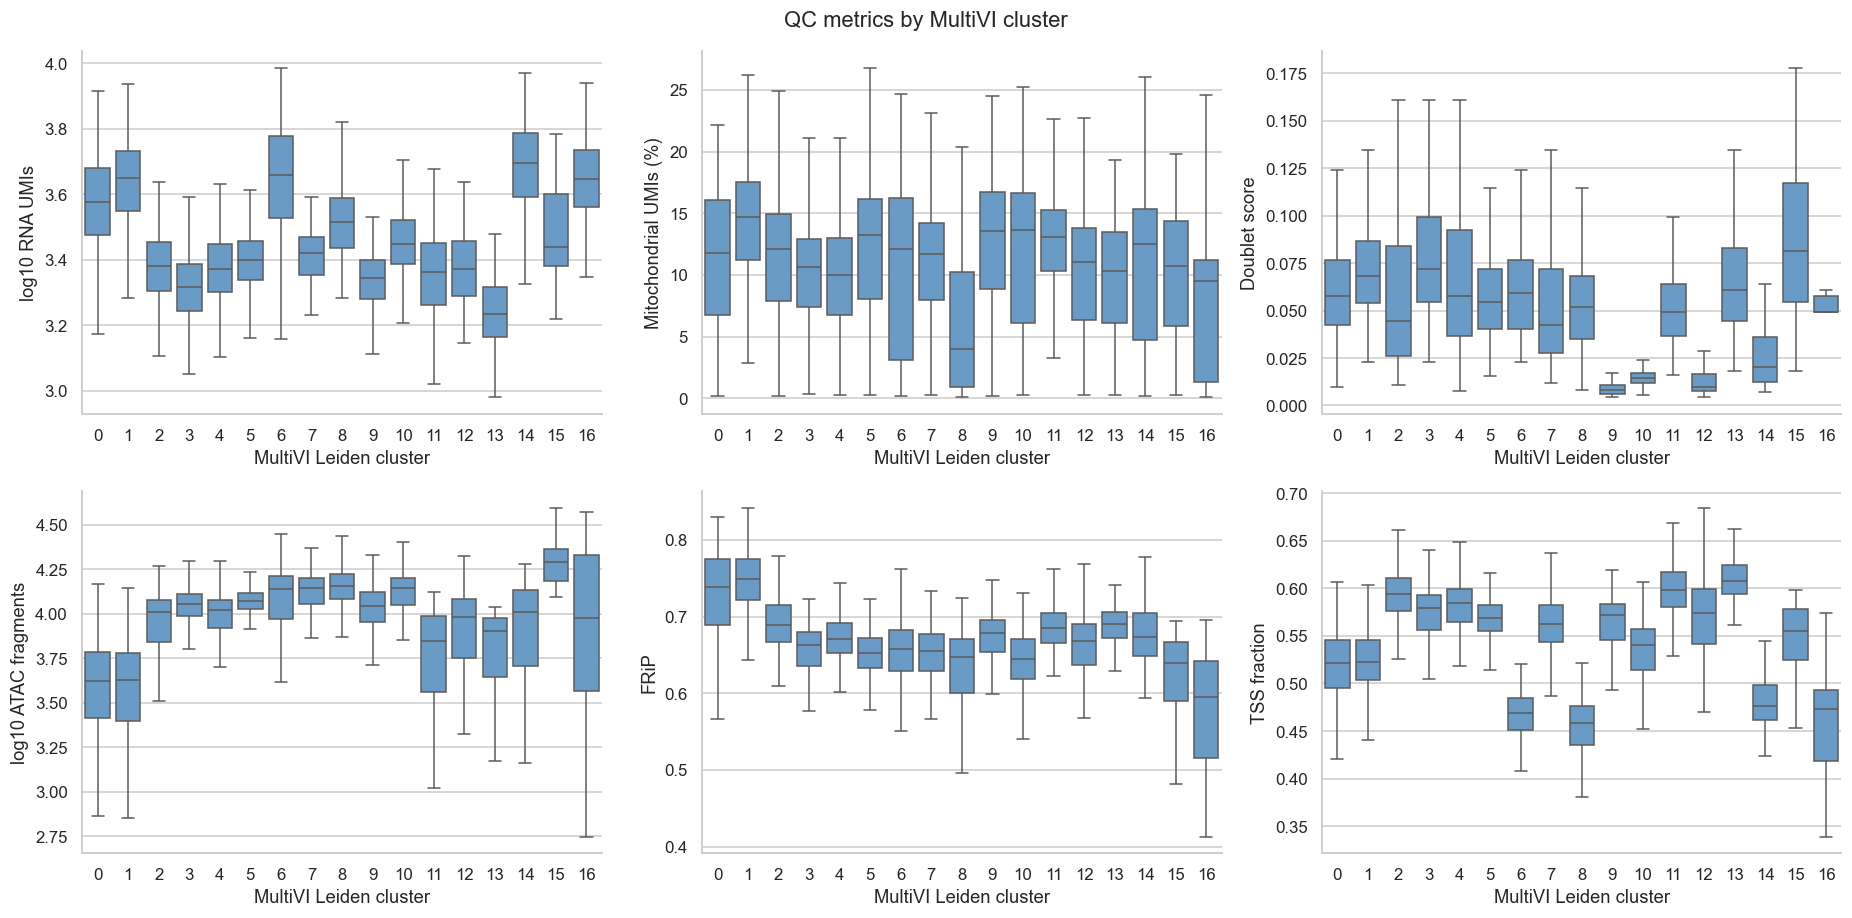

In [11]:
correlations = latent_qc_correlations(container.obsm["X_multivi"], container.obs)
display(correlations.reindex(correlations["correlation"].abs().sort_values(ascending=False).index).head(10))

fig = plot_latent_qc_correlations(correlations)
save_figure(fig, figure_dir / "08_multivi_latent_qc.png")
plt.show()

fig = plot_multivi_umap(container)
save_figure(fig, figure_dir / "09_multivi_umap.png")
plt.show()

fig = plot_cluster_qc(container.obs)
save_figure(fig, figure_dir / "10_multivi_cluster_qc.png")
plt.show()

## 11. Name joint clusters from observed RNA markers

Each joint cluster is scored with several markers per broad PBMC population on
observed, log-normalized RNA. A cluster takes the best-scoring population when
that score is at least 0.3 and leads the runner-up by at least 0.2; otherwise
it stays `Unresolved`. The names are provisional labels supported by marker
evidence, not validated cell identities.

In [12]:
rna_paired.obs["leiden_multivi"] = container.obs["leiden_multivi"].to_numpy()
scores = score_populations(rna_paired, "leiden_multivi", seed=17)
assignment = assign_populations(scores)
display(scores.round(2).join(assignment[["population", "margin"]].round(2)))

population = container.obs["leiden_multivi"].map(assignment["population"]).astype(str)
order = [name for name in [*POPULATION_MARKERS, "Unresolved"] if name in set(population)]
container.obs["population"] = pd.Categorical(population, categories=order)
rna_paired.obs["population"] = container.obs["population"].values
atac_paired.obs["population"] = container.obs["population"].values
palette = population_palette(order)
display(container.obs["population"].value_counts().to_frame("nuclei"))

# Overall latent-QC correlations mix cell-type differences with technical ones.
# Centering within populations asks what remains among nuclei of one type.
correlations_within = latent_qc_correlations_within(container.obsm["X_multivi"], container.obs, "population")
display(
    correlations_within.reindex(correlations_within["correlation_within"].abs().sort_values(ascending=False).index).head(8)
)

,T cells,NK cells,B cells,CD14 monocytes,FCGR3A monocytes,Conventional DCs,Plasmacytoid DCs,population,margin
leiden_multivi,,,,,,,,,
0,-0.61,-0.16,-0.24,1.84,0.00,-0.02,-0.06,CD14 monocytes,1.84
1,-0.65,-0.18,-0.28,1.68,0.16,0.02,0.00,CD14 monocytes,1.52
10,-0.55,-0.15,2.33,-0.42,-0.15,0.06,-0.07,B cells,2.27
11,0.62,-0.09,-0.18,-0.41,-0.13,-0.02,-0.05,T cells,0.65
12,-0.38,2.17,-0.27,-0.35,0.06,-0.04,-0.11,NK cells,2.11
13,0.49,-0.09,-0.18,-0.36,-0.11,-0.02,-0.03,T cells,0.51
14,-0.66,-0.15,-0.32,0.38,1.75,-0.03,-0.02,FCGR3A monocytes,1.37
15,0.58,-0.14,-0.24,-0.38,-0.16,-0.03,-0.09,T cells,0.61
16,-0.60,-0.11,-0.21,-0.47,-0.20,-0.01,1.21,Plasmacytoid DCs,1.23


,nuclei
population,
T cells,1074
CD14 monocytes,902
NK cells,342
B cells,269
FCGR3A monocytes,102
Plasmacytoid DCs,29


,component,metric,correlation_within
52,9,log10_fragments,-0.536455
74,9,tss_fraction,0.481661
63,9,frip,0.450772
68,3,tss_fraction,-0.415106
22,1,intronic_fraction,0.411076
46,3,log10_fragments,0.408730
50,7,log10_fragments,0.396903
57,3,frip,-0.356407


## 12. Check the labels against observed accessibility

The RNA panel shows the markers used to name clusters. The ATAC panel shows,
for the same genes, the fraction of nuclei with at least one fragment in a peak
that 10x annotates as that gene's promoter (an x marks genes with no annotated
promoter peak). Both panels are observed data. Accessibility was not used to
assign labels, although it did shape the joint clusters that were labelled.

The locus plot shows, for each population, the marker locus whose most
population-specific peak (within 20 kb of the gene's annotated TSS) differs
most from every other population. `marker_locus_specificity` reports that
value for every marker, including the ones not plotted.

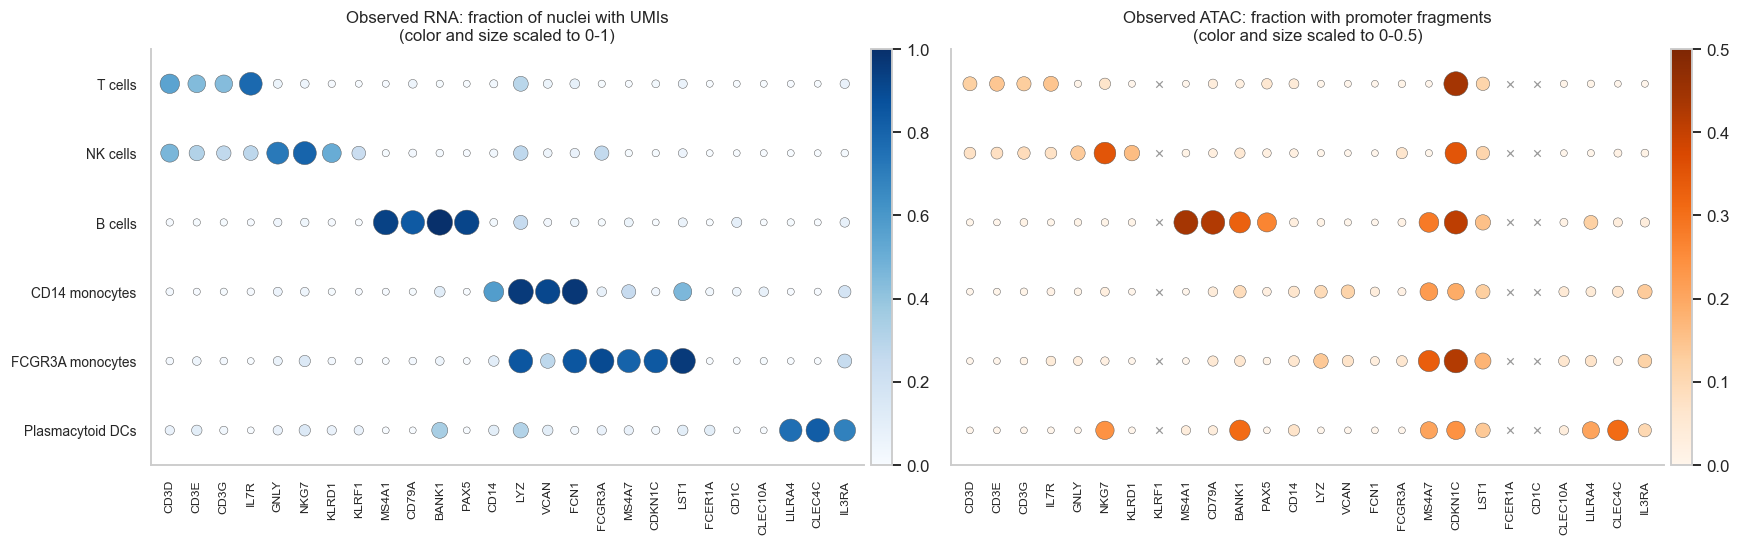

,population,gene,n_peaks,best_peak,fraction_in_population,max_fraction_elsewhere,specificity
0,T cells,CD3D,6,chr11:118342302-118343131,0.124,0.076,0.048
1,T cells,CD3E,9,chr11:118304297-118305204,0.143,0.079,0.064
2,T cells,CD3G,6,chr11:118342302-118343131,0.124,0.076,0.048
3,T cells,IL7R,5,chr5:35854091-35854847,0.286,0.070,0.216
4,NK cells,GNLY,11,chr2:85693886-85694802,0.135,0.029,0.105
5,NK cells,NKG7,7,chr19:51372437-51373359,0.351,0.241,0.109
6,NK cells,KLRD1,5,chr12:10303890-10304777,0.108,0.007,0.101
7,NK cells,KLRF1,3,chr12:9829270-9830123,0.015,0.004,0.011
8,B cells,MS4A1,4,chr11:60455252-60456170,0.439,0.034,0.404
9,B cells,CD79A,8,chr19:41876966-41877693,0.424,0.049,0.375


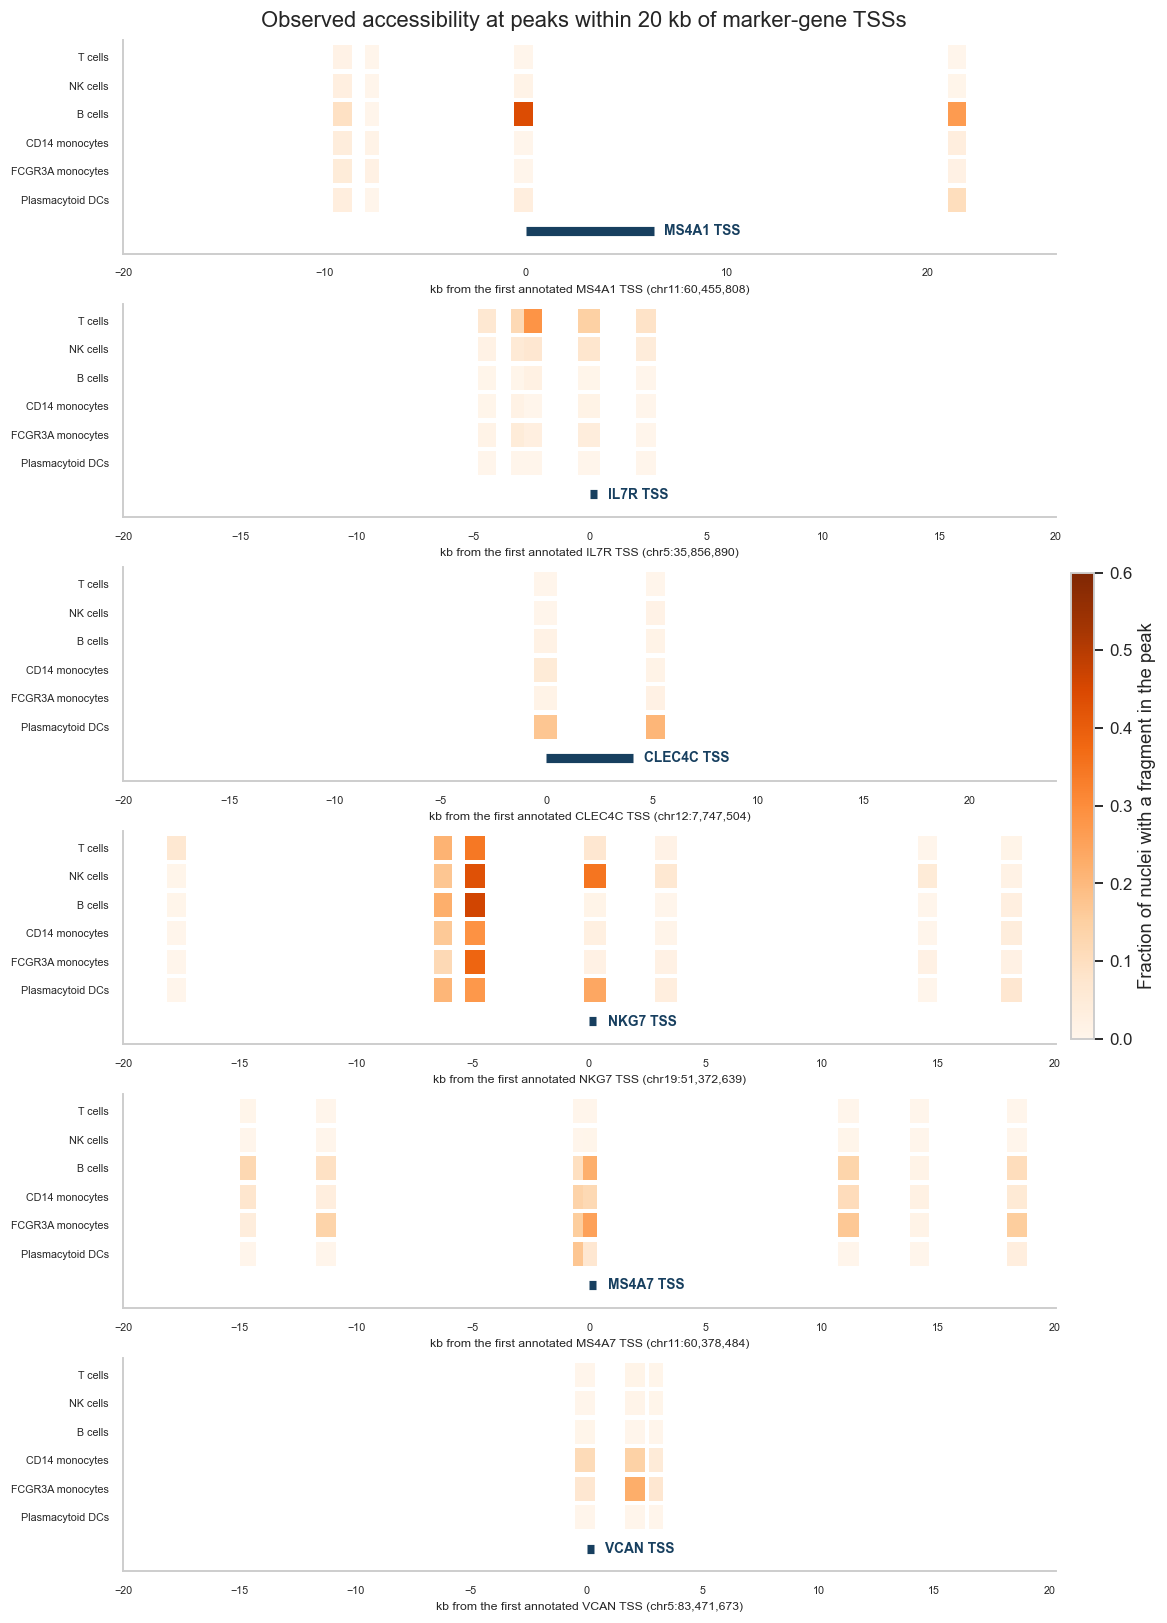

In [13]:
gene_order = list(dict.fromkeys(gene for genes_ in POPULATION_MARKERS.values() for gene in genes_))
evidence = marker_evidence(rna_paired, atac_paired, "population", gene_order)
fig = plot_marker_evidence(evidence, "population", gene_order)
save_figure(fig, figure_dir / "11_marker_evidence.png")
plt.show()

locus_specificity = marker_locus_specificity(atac_paired, rna_paired.var, atac_paired.obs["population"])
display(locus_specificity.round(3))
loci = [
    locus_accessibility(atac_paired, rna_paired.var, atac_paired.obs["population"], gene)
    for gene in choose_marker_loci(locus_specificity)
]
fig = plot_marker_loci(loci)
save_figure(fig, figure_dir / "14_marker_loci.png")
plt.show()

## 13. Compare what RNA, ATAC, and the joint model resolve

Coloring all three embeddings with the same labels shows which populations
each measurement separates on its own. The contingency tables show how each
labelled population is distributed across RNA-only and ATAC-only clusters.
The adjusted Rand index (ARI) summarizes agreement between two clusterings;
it is also lowered when one clustering simply has more clusters than the
other, so compare it alongside the cluster counts.

,comparison,adjusted_rand_index
0,leiden_multivi vs leiden_rna,0.580
1,leiden_multivi vs leiden_atac,0.450
2,leiden_rna vs leiden_atac,0.649


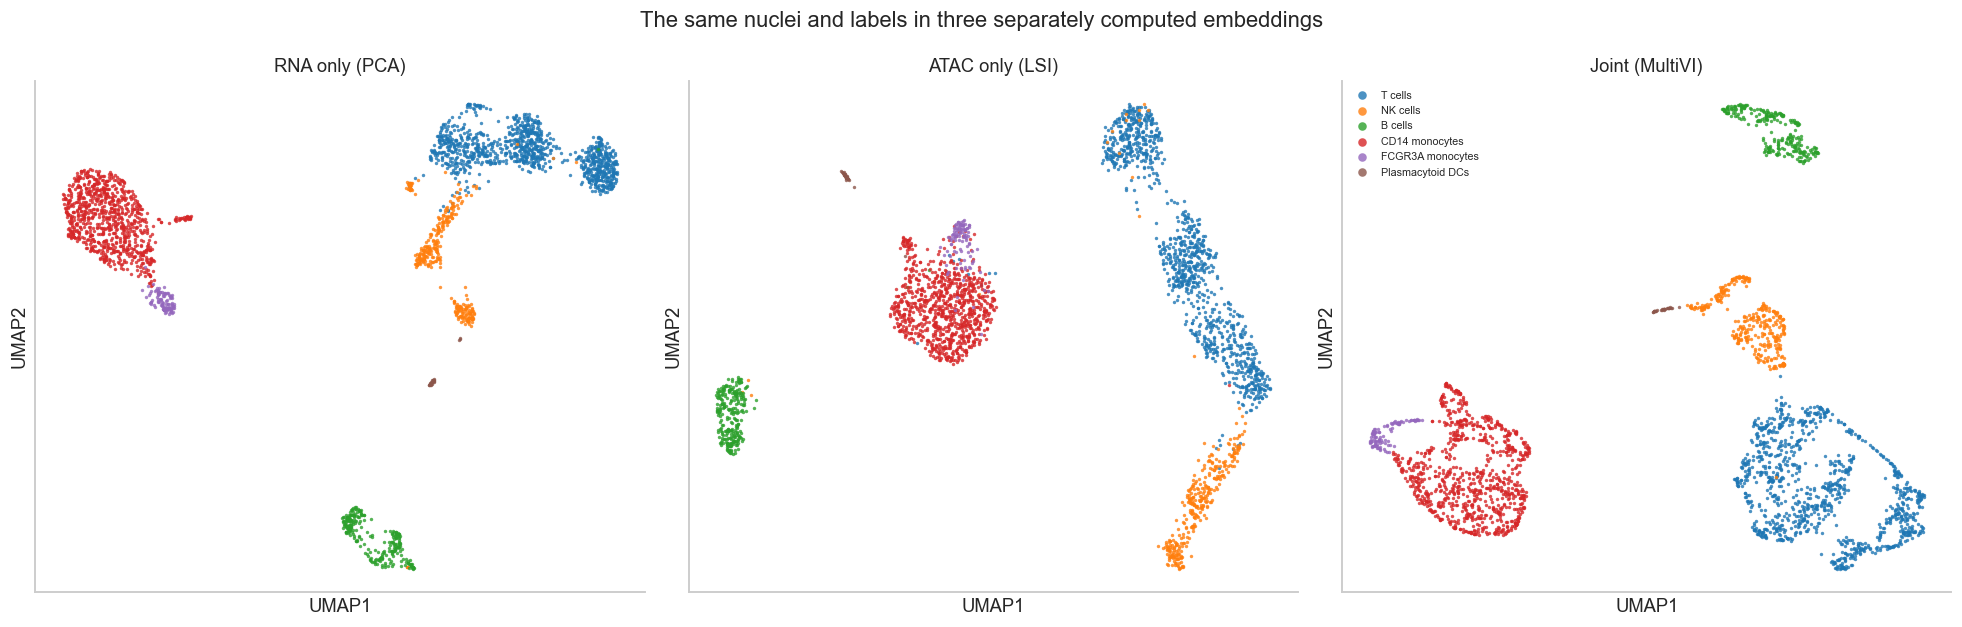

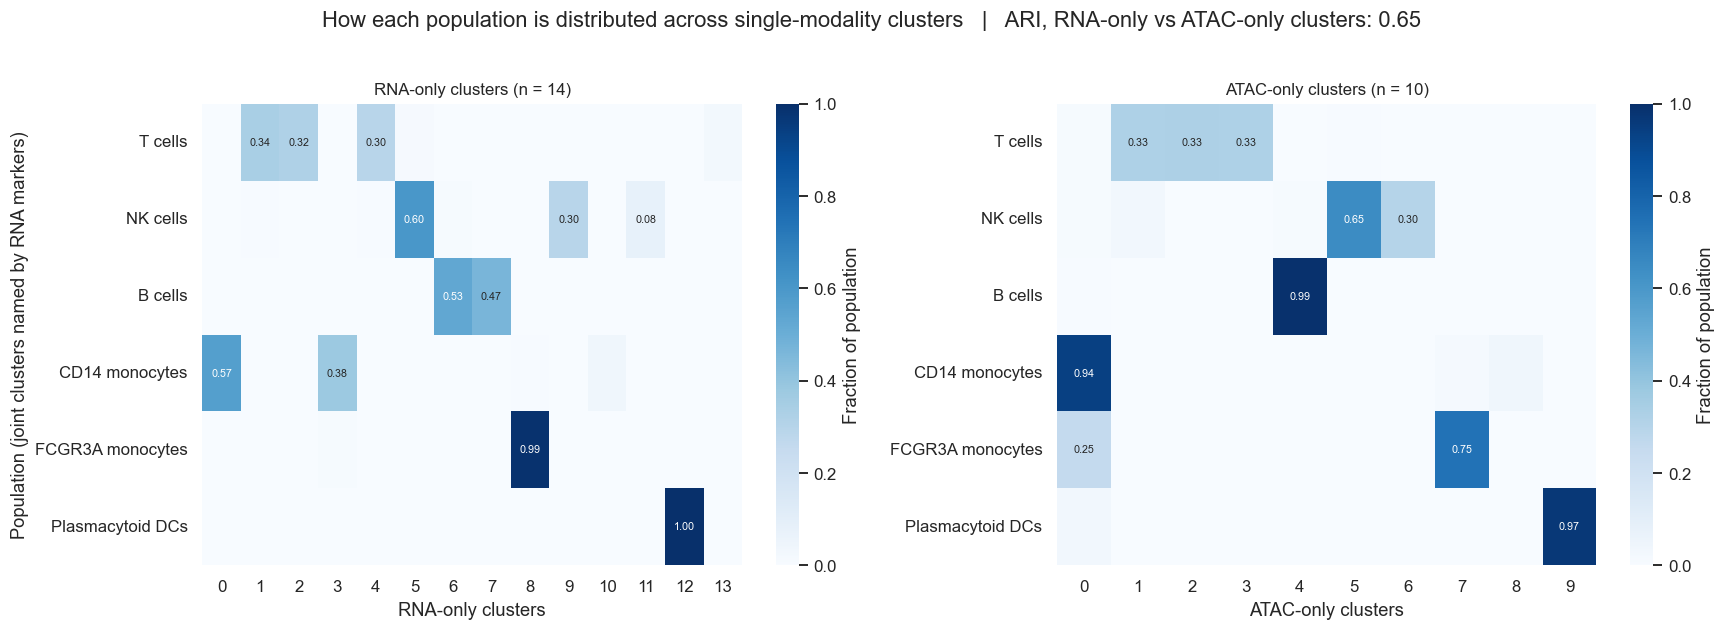

In [14]:
agreement = clustering_agreement(container.obs, "leiden_multivi", ["leiden_rna", "leiden_atac"])
agreement = pd.concat(
    [agreement, clustering_agreement(container.obs, "leiden_rna", ["leiden_atac"])],
    ignore_index=True,
)
display(agreement.round(3))

fig = plot_embedding_comparison(container, "population", palette)
save_figure(fig, figure_dir / "12_embedding_comparison.png")
plt.show()

fig = plot_cluster_agreement(container.obs, "population", agreement)
save_figure(fig, figure_dir / "13_cluster_agreement.png")
plt.show()

## 14. Inspect what the joint clusters add

The broad labels hide structure inside each population. Three checks use
observed RNA only:

- T-cell state markers in each joint T-cell cluster, including markers commonly
  used for regulatory T cells (FOXP3, IL2RA, CTLA4, IKZF2, RTKN2, TIGIT);
- conventional DC markers (FCER1A, CD1C, CLEC10A) in the clusters of each
  representation, to see whether a small population is kept or merged;
- the CD14 monocyte joint clusters, split by whether their median ATAC fragment
  count is below the population median, with a comparison of observed RNA
  between the two groups. Nuclei in the RNA-only cluster with the strongest
  DC-marker detection are left out of that comparison.

In [15]:
t_like = container.obs["population"].astype(str).isin(["T cells", "Unresolved"]).to_numpy()
t_states = marker_detection(rna_paired[t_like], container.obs.loc[t_like, "leiden_multivi"], T_STATE_MARKERS)
t_states_rna = marker_detection(rna_paired[t_like], container.obs.loc[t_like, "leiden_rna"], T_STATE_MARKERS)
t_states_atac = marker_detection(rna_paired[t_like], container.obs.loc[t_like, "leiden_atac"], T_STATE_MARKERS)
display(t_states.round(2))
print("Same markers, grouped by RNA-only and by ATAC-only clusters:")
display(t_states_rna.round(2))
display(t_states_atac.round(2))

dc_tables = {
    key: marker_detection(rna_paired, container.obs[key], DC_MARKERS)
    for key in ["leiden_rna", "leiden_atac", "leiden_multivi"]
}
for key, table in dc_tables.items():
    print(key)
    display(table.sort_values("CLEC10A", ascending=False).head(3).round(2))
dc_signal = dc_tables["leiden_rna"][["FCER1A", "CD1C", "CLEC10A"]].mean(axis=1)
dc_like = container.obs["leiden_rna"].astype(str).eq(str(dc_signal.idxmax()))
display(container.obs.loc[dc_like, "leiden_multivi"].value_counts().to_frame("DC-like nuclei by joint cluster"))

,n_nuclei,CD4,CD8A,CD8B,CCR7,SELL,LEF1,IL7R,GZMK,CCL5,NKG7,FOXP3,IL2RA,CTLA4,IKZF2,RTKN2,TIGIT
11,109,0.01,0.53,0.52,0.71,0.68,0.95,0.74,0.00,0.00,0.07,0.00,0.00,0.02,0.11,0.00,0.00
13,104,0.25,0.00,0.01,0.48,0.59,0.85,0.68,0.01,0.02,0.04,0.03,0.09,0.03,0.16,0.09,0.02
15,60,0.17,0.37,0.38,0.75,0.75,0.95,0.85,0.05,0.07,0.05,0.00,0.03,0.02,0.12,0.05,0.00
3,219,0.31,0.01,0.03,0.70,0.68,0.91,0.80,0.00,0.04,0.04,0.00,0.01,0.02,0.03,0.01,0.00
4,213,0.31,0.01,0.03,0.39,0.47,0.80,0.75,0.01,0.03,0.03,0.04,0.14,0.04,0.12,0.08,0.06
5,207,0.02,0.54,0.66,0.68,0.67,0.96,0.73,0.01,0.03,0.05,0.00,0.00,0.00,0.05,0.01,0.00
7,162,0.31,0.06,0.09,0.20,0.24,0.58,0.90,0.10,0.16,0.09,0.03,0.20,0.04,0.07,0.07,0.02


Same markers, grouped by RNA-only and by ATAC-only clusters:


,n_nuclei,CD4,CD8A,CD8B,CCR7,SELL,LEF1,IL7R,GZMK,CCL5,NKG7,FOXP3,IL2RA,CTLA4,IKZF2,RTKN2,TIGIT
1,365,0.29,0.01,0.02,0.64,0.66,0.88,0.75,0.00,0.03,0.03,0.00,0.02,0.02,0.05,0.02,0.00
11,4,0.25,0.00,0.00,0.00,0.25,0.50,1.00,0.25,0.25,0.75,0.00,0.25,0.00,0.50,0.00,0.00
13,27,0.19,0.00,0.04,0.19,0.44,0.85,0.26,0.00,0.00,0.07,0.41,0.59,0.19,0.85,0.74,0.26
2,346,0.02,0.55,0.62,0.71,0.69,0.96,0.75,0.01,0.03,0.06,0.00,0.00,0.01,0.07,0.00,0.00
4,317,0.34,0.03,0.05,0.29,0.35,0.70,0.87,0.04,0.07,0.04,0.02,0.16,0.03,0.06,0.04,0.03
5,15,0.13,0.27,0.20,0.33,0.40,0.67,0.87,0.60,0.60,0.20,0.00,0.00,0.07,0.07,0.07,0.00


,n_nuclei,CD4,CD8A,CD8B,CCR7,SELL,LEF1,IL7R,GZMK,CCL5,NKG7,FOXP3,IL2RA,CTLA4,IKZF2,RTKN2,TIGIT
0,9,0.00,0.56,0.44,0.67,0.44,0.89,0.56,0.00,0.00,0.22,0.00,0.00,0.00,0.00,0.00,0.00
1,350,0.02,0.52,0.59,0.71,0.69,0.96,0.75,0.01,0.04,0.05,0.00,0.00,0.01,0.09,0.01,0.00
2,355,0.32,0.02,0.05,0.29,0.36,0.70,0.83,0.05,0.07,0.05,0.05,0.19,0.05,0.11,0.09,0.05
3,351,0.30,0.03,0.04,0.64,0.67,0.89,0.75,0.00,0.03,0.03,0.00,0.03,0.02,0.05,0.03,0.00
5,8,0.00,0.25,0.38,0.12,0.25,0.62,1.00,0.75,0.75,0.62,0.00,0.00,0.12,0.12,0.00,0.00
9,1,0.00,1.00,1.00,0.00,1.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


leiden_rna


...

leiden_atac


,n_nuclei,FCER1A,CD1C,CLEC10A,CD14,LYZ
8,37,0.68,0.76,0.73,0.22,1.00
0,889,0.01,0.02,0.05,0.57,0.94
1,361,0.00,0.00,0.01,0.02,0.31


leiden_multivi


,n_nuclei,FCER1A,CD1C,CLEC10A,CD14,LYZ
6,168,0.17,0.20,0.23,0.45,0.99
1,244,0.00,0.03,0.08,0.66,0.97
0,344,0.00,0.01,0.02,0.58,0.94


,DC-like nuclei by joint cluster
leiden_multivi,
6,38
0,0
9,0
15,0
14,0
13,0
12,0
11,0
10,0


In [16]:
depth_group = split_population_by_depth(container.obs, "CD14 monocytes")
monocyte_clusters = sorted(container.obs.loc[depth_group.index, "leiden_multivi"].astype(str).unique())
monocyte_qc = cluster_qc_table(container.obs, monocyte_clusters)
cluster_group = container.obs.loc[depth_group.index, "leiden_multivi"].astype(str).groupby(depth_group).unique()
monocyte_qc["depth_group"] = [
    next(group for group, members in cluster_group.items() if cluster in members) for cluster in monocyte_qc.index
]
display(monocyte_qc.round(3))

monocyte_groups = depth_group[~dc_like.reindex(depth_group.index).to_numpy()]
print(f"DC-like nuclei left out: {int(dc_like.reindex(depth_group.index).sum())}")
display(monocyte_groups.value_counts().to_frame("nuclei"))
monocyte_de = compare_rna_groups(rna_paired, monocyte_groups)
display(monocyte_de.loc[monocyte_de["pvals_adj"] < 0.05, ["higher_in", "names", "logfoldchanges", "pvals_adj", "pct_nz_group", "pct_nz_reference"]])

# Do the genes that differ track mitochondrial RNA?
significant = monocyte_de.loc[monocyte_de["pvals_adj"] < 0.05, "names"].unique().tolist()
mito_link = mitochondrial_link(rna_paired, significant)
display(mito_link)

,n_nuclei,total_counts,pct_counts_mt,atac_fragments,frip,tss_fraction,nucleosome_signal,doublet_score,depth_group
leiden_multivi,,,,,,,,,
0,344,3761.5,11.791,4183.0,0.739,0.521,0.519,0.058,lower ATAC depth
1,244,4463.5,14.700,4224.0,0.750,0.523,0.487,0.068,lower ATAC depth
6,168,4544.5,12.136,13738.5,0.658,0.469,0.585,0.059,higher ATAC depth
8,146,3269.0,3.958,14281.0,0.647,0.458,0.629,0.052,higher ATAC depth


DC-like nuclei left out: 38


,nuclei
depth_group,
lower ATAC depth,588
higher ATAC depth,276


,higher_in,names,logfoldchanges,pvals_adj,pct_nz_group,pct_nz_reference
36586,higher ATAC depth,MTRNR2L8,-1.332519,2.303274e-10,0.391304,0.685374
36587,higher ATAC depth,MTRNR2L12,-1.690224,9.805147e-25,0.786232,0.976190
36588,lower ATAC depth,MTRNR2L12,1.690224,9.805147e-25,0.976190,0.786232
36589,lower ATAC depth,MTRNR2L8,1.332519,2.303274e-10,0.685374,0.391304


,gene,spearman_rho_with_pct_mt,p_value,n_nuclei
0,MTRNR2L8,0.366414,3.915634e-87,2718
1,MTRNR2L12,0.632286,2.106031e-303,2718


Two small groups are clearest in the RNA-only clustering: the cluster with the
strongest conventional-DC markers and the cluster with the strongest
regulatory-T markers. The next cell asks whether the joint clustering gives
either group its own cluster as the Leiden resolution increases, and how the
ATAC-only clustering handles them. `share_of_cluster` is the fraction of the
best-matching cluster made up of the group.

In [17]:
small_groups = small_group_masks(container.obs, dc_tables["leiden_rna"], t_states_rna)
small_group_check = resolution_check(container, small_groups, [0.8, 1.2, 1.6, 2.0, 3.0], seed=17)
display(small_group_check.round(2))

,group,clustering,resolution,n_clusters,best_cluster,share_of_cluster,group_nuclei_in_cluster,group_size
0,DC-like (RNA-only cluster),ATAC-only,NaN,10,8,0.86,32,38
1,Treg-like (RNA-only cluster),ATAC-only,NaN,10,2,0.07,24,27
2,DC-like (RNA-only cluster),joint,0.8,17,6,0.23,38,38
3,Treg-like (RNA-only cluster),joint,0.8,17,4,0.08,18,27
4,DC-like (RNA-only cluster),joint,1.2,23,18,0.41,38,38
5,Treg-like (RNA-only cluster),joint,1.2,23,21,0.34,21,27
6,DC-like (RNA-only cluster),joint,1.6,28,22,0.54,38,38
7,Treg-like (RNA-only cluster),joint,1.6,28,24,0.33,21,27
8,DC-like (RNA-only cluster),joint,2.0,33,20,0.52,38,38
9,Treg-like (RNA-only cluster),joint,2.0,33,24,0.33,21,27


## 15. Save compact, reusable results

The trained model and large objects stay outside Git. The compact results
contain thresholds, the retention table, the latent audit, cluster marker
scores, marker evidence, clustering agreement, and per-nucleus metadata with
all three UMAPs.

In [18]:
tables = {
    "retention": retention_table(rna.obs),
    "qc_flag_counts": qc_reason_counts(rna.obs),
    "observed_library_check": check_observed_libraries(mdata),
    "lsi_depth_correlations": lsi_depth,
    "multivi_latent_qc_correlations": correlations,
    "multivi_latent_qc_correlations_within_population": correlations_within,
    "cluster_marker_scores": scores.join(assignment),
    "marker_evidence": evidence,
    "marker_locus_specificity": locus_specificity,
    "t_cell_state_markers": t_states,
    "t_cell_state_markers_by_rna_cluster": t_states_rna,
    "t_cell_state_markers_by_atac_cluster": t_states_atac,
    "dc_markers_by_rna_cluster": dc_tables["leiden_rna"],
    "dc_markers_by_atac_cluster": dc_tables["leiden_atac"],
    "dc_markers_by_joint_cluster": dc_tables["leiden_multivi"],
    "cd14_monocyte_cluster_qc": monocyte_qc,
    "cd14_monocyte_depth_group_rna_comparison": monocyte_de,
    "small_group_resolution_check": small_group_check,
    "depth_group_gene_mito_link": mito_link,
    "clustering_agreement": agreement,
}
write_results(container, thresholds, tables, results_dir)
print("Results written to", results_dir.relative_to(repo_root))

Results written to source/transcriptomics/multiome_tutorial/results
